# 08 · TF-IDF dari vocabulary ke cosine

**Tujuan:** Menunjukkan vektor TF-IDF, bobot kata, dan cosine similarity.

**Alur:** input → proses yang terlihat → pengecekan → output. Semua label kompetensi lama hanya dipakai sebagai referensi audit, bukan kebenaran relevansi.

## 0. Setup dan validasi sumber data

In [1]:
from pathlib import Path
import os, sys, json, time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT/'data'/'dataset_buku_2000.csv').exists(): ROOT=ROOT.parent
assert (ROOT/'data'/'dataset_buku_2000.csv').exists(), f'Folder proyek tidak ditemukan dari {Path.cwd()}'
sys.path.insert(0,str(ROOT))
from src import engine
DATA, OUT, FIG, MODELS = [ROOT/x for x in ('data','outputs','figures','models')]
for folder in (OUT,FIG,MODELS): folder.mkdir(exist_ok=True)
books, comps = engine.load_data()
print('Dataset:',len(books),'buku;',len(comps),'kompetensi')
assert books.book_id.is_unique and comps.competency_id.is_unique

Dataset: 973 buku; 67 kompetensi


## 1. Input yang sama

In [2]:
clean=pd.read_csv(OUT/'dataset_buku_bersih.csv',dtype=str).fillna('')
profiles=pd.read_csv(OUT/'profil_kompetensi_query.csv',dtype=str).fillna('')
assert len(clean)==len(books) and len(profiles)==len(comps)
books['teks_buku']=clean.set_index('book_id').reindex(books.book_id)['teks_model'].fillna('').to_numpy() if 'teks_model' in clean.columns else books.teks_buku
comps['teks_query']=profiles.set_index('competency_id').reindex(comps.competency_id)['teks_query'].fillna('').to_numpy() if 'teks_query' in profiles.columns else comps.teks_query
assert books.teks_buku.str.len().gt(0).all()
print('Contoh buku:',books[['judul','teks_buku']].head(2).to_string(index=False,max_colwidth=110))
print('Contoh kompetensi:',comps[['competency_name','teks_query']].head(2).to_string(index=False,max_colwidth=110))

Contoh buku:                                judul                                                                                                      teks_buku
            Business Growth Strategy Business Growth Strategy Business Growth Strategy Introduction I wrote this book, “Business Growth Strategy...
Mastering Business Growth Strategies Mastering Business Growth Strategies Mastering Business Growth Strategies Mastering Business Growth Strateg...
Contoh kompetensi:      competency_name                                                                          teks_query
Business Development       Business Development business growth; business strategy; market opportunities
Marketing Management Marketing Management marketing strategy; marketing analytics; customer segmentation


## 2. Fit vocabulary, IDF, dan transformasi

Vocabulary dihitung hanya dari buku, lalu query ditransformasi memakai vocabulary yang sama.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
vectorizer=TfidfVectorizer(stop_words='english',ngram_range=(1,2),max_features=40000,sublinear_tf=True)
t0=time.perf_counter()
X=vectorizer.fit_transform(books.teks_buku)
Q=vectorizer.transform(comps.teks_query)
print('Book sparse matrix:',X.shape,'Query matrix:',Q.shape,'nonzero elements:',X.getnnz())
vocab=np.array(vectorizer.get_feature_names_out())
vectorizer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    max_features=40000,
    sublinear_tf=True
)
t0 = time.perf_counter()
X = vectorizer.fit_transform(books.teks_buku)
Q = vectorizer.transform(comps.teks_query)

print('Book sparse matrix:', X.shape, 'Query matrix:', Q.shape, 'nonzero elements:', X.getnnz())

vocab = np.array(vectorizer.get_feature_names_out())
first_book_tfidf = X.getrow(0).toarray().ravel()
idx = np.argsort(-first_book_tfidf)[:15]

display(pd.DataFrame({
    'fitur': vocab[idx],
    'bobot_tfidf_buku_pertama': first_book_tfidf[idx]
}))
first_book_tfidf = X.getrow(0).toarray().ravel()
idx = np.argsort(-first_book_tfidf)[:15]

display(pd.DataFrame({
    'fitur': vocab[idx],
    'bobot_tfidf_buku_pertama': first_book_tfidf[idx]
}))

Book sparse matrix: (973, 40000) Query matrix: (67, 40000) nonzero elements: 114189
Book sparse matrix: (973, 40000) Query matrix: (67, 40000) nonzero elements: 114189


,fitur,bobot_tfidf_buku_pertama
0,growth strategy,0.161767
1,business growth,0.161541
2,growth,0.145663
3,sustain growth,0.139368
4,sustain,0.138272
5,create value,0.131507
6,growth strategies,0.115079
7,grow sustain,0.112441
8,grow business,0.112441
9,grow,0.107710


,fitur,bobot_tfidf_buku_pertama
0,growth strategy,0.161767
1,business growth,0.161541
2,growth,0.145663
3,sustain growth,0.139368
4,sustain,0.138272
5,create value,0.131507
6,growth strategies,0.115079
7,grow sustain,0.112441
8,grow business,0.112441
9,grow,0.107710


## 3. Demonstrasi cosine similarity

TF-IDF dan BM25 dapat menghasilkan ranking serupa karena keduanya berbasis istilah.

In [4]:
scores=cosine_similarity(Q,X)
manual = float(Q.getrow(0).multiply(X.getrow(0)).sum())
print('Perkalian dot product query-buku pertama:',manual,'vs matriks:',scores[0,0])
assert np.isclose(manual,scores[0,0])
print('Skor matrix:',scores.shape,'nilai min/max:',scores.min(),scores.max())

Perkalian dot product query-buku pertama: 0.153217041641265 vs matriks: 0.15321704164126515
Skor matrix: (67, 973) nilai min/max: 0.0 0.5189568440042901


## 4. Hasil Top 10 dan artefak

Simpan vectorizer agar vocabulary pelatihan tidak berubah saat inferensi.

,ranking,judul,skor_asli
0,1,Business Development For Dummies,0.172664
1,2,Business Growth Strategy,0.153217
2,3,Mastering Business Strategy,0.146129
3,4,AI-Powered Business Growth Strategies,0.136585
4,5,Strategic Internet Business Management - an As...,0.129139
5,6,Mastering Business Growth Strategies,0.126801
6,7,Analysis of growth strategies. Organic vs. ino...,0.100525
7,8,Manufacturing Strategy,0.098235
8,9,Emerging Business Opportunities in Africa: Mar...,0.084888
9,10,Developing a market expansion strategy of a UK...,0.083674


Semua pasangan: 65191


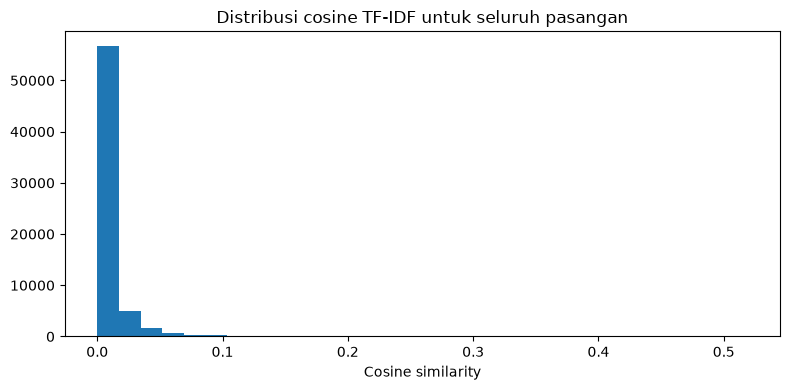

In [5]:
elapsed=time.perf_counter()-t0
pairs,top=engine.save_all_pairs(scores,books,comps,'tfidf')
pd.DataFrame([{'model':'tfidf','waktu_total_detik':elapsed,'jumlah_pasangan':len(pairs)}]).to_csv(OUT/'runtime_tfidf.csv',index=False)
import joblib
joblib.dump(vectorizer,MODELS/'tfidf_vectorizer.joblib')
q=top[top.competency_id==comps.competency_id.iloc[0]]
display(q[['ranking','judul','skor_asli']]);print('Semua pasangan:',len(pairs))
fig,ax=plt.subplots(figsize=(8,4));ax.hist(scores.flatten(),bins=30);ax.set_title('Distribusi cosine TF-IDF untuk seluruh pasangan');ax.set_xlabel('Cosine similarity');plt.tight_layout();fig.savefig(FIG/'08_tfidf_score_distribution.png',dpi=130);plt.show()

## Kesimpulan tahap dan serah-terima

Periksa tabel/grafik yang tercetak, simpan artefak hasil, lalu lanjut ke notebook berikutnya. **Kesamaan kata, similarity dan percentile bukan ground truth relevansi.** Jangan mengklaim metrik akurasi tanpa penilaian independen.